# RadioML RML2016.10a - Data Exploration & Visualization

This notebook explores the `RML2016.10a` radio signal dataset and shows how different modulation types look across clean and noisy channels.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_rml2016a, summarize_dataset, print_summary
from src.visualization import plot_constellation_grid, plot_fft_grid, DEFAULT_MODULATIONS, DEFAULT_SNRS

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "RML2016.10a_dict.pkl"
data = load_rml2016a(str(DATA_PATH))
summary = summarize_dataset(str(DATA_PATH), data)
print_summary(summary)

RML2016.10a Dataset Verification Summary
File name          : RML2016.10a_dict.pkl
Format             : .pkl
File size          : 611.23 MB (640,919,653 bytes)
Modulation classes : 11 -> ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
SNR levels (dB)    : 20 -> [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]
Total examples     : 220,000
Examples/(mod,SNR) : 1000 (balanced=True)
Observation shape  : (2, 128) (2=I/Q, 128=time samples)
Data type          : float32


## 1. What is in the dataset?
- **11 modulation types** (8 digital, 3 analog) across **20 noise levels** (SNR from `-20 dB` very noisy to `+18 dB` very clean).
- **220,000 examples total** — perfectly balanced (`1,000` examples for every modulation at every SNR).
- Each example is a **`2 × 128`** array: **I** (in-phase) and **Q** (quadrature) over 128 time steps. Together, I and Q capture the signal's strength (amplitude) and timing/angle (phase), which is what separates one modulation from another.

In [2]:
pd.DataFrame([
    {"Modulation": mod, "SNR Levels": len(summary["snrs"]), "Total Examples": sum(data[(mod, s)].shape[0] for s in summary["snrs"])}
    for mod in summary["modulations"]
])

,Modulation,SNR Levels,Total Examples
0,8PSK,20,20000
1,AM-DSB,20,20000
2,AM-SSB,20,20000
3,BPSK,20,20000
4,CPFSK,20,20000
5,GFSK,20,20000
6,PAM4,20,20000
7,QAM16,20,20000
8,QAM64,20,20000
9,QPSK,20,20000


## 2. Inspect Any Signal
Change `MOD` or `SNR` below and re-run to see the signal in three views:
1. **Time:** How I and Q change over time.
2. **Constellation (I vs Q):** The shape/pattern of the signal points.
3. **Spectrum (FFT):** Which frequencies carry the signal's energy.

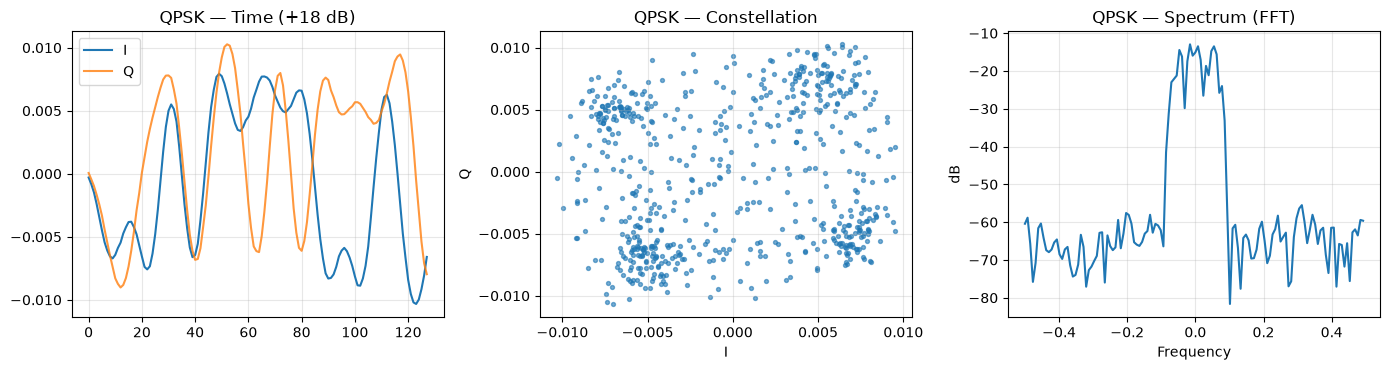

In [3]:
MOD = "QPSK"   # BPSK, QPSK, 8PSK, QAM16, QAM64, PAM4, GFSK, CPFSK, AM-DSB, AM-SSB, WBFM
SNR = 18       # Even values from -20 to 18
IDX = 0        # 0 to 999

I, Q = data[(MOD, SNR)][IDX]
frames = data[(MOD, SNR)][IDX : IDX + 5]

freqs = np.fft.fftshift(np.fft.fftfreq(128))
spec_db = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft((I + 1j * Q) * np.hanning(128)))) + 1e-12)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].plot(I, label="I"); axes[0].plot(Q, label="Q", alpha=0.8)
axes[0].set_title(f"{MOD} — Time ({SNR:+d} dB)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(frames[:, 0, :].ravel(), frames[:, 1, :].ravel(), s=8, alpha=0.6)
axes[1].set_title(f"{MOD} — Constellation"); axes[1].set_xlabel("I"); axes[1].set_ylabel("Q"); axes[1].grid(alpha=0.3)

axes[2].plot(freqs, spec_db)
axes[2].set_title(f"{MOD} — Spectrum (FFT)"); axes[2].set_xlabel("Frequency"); axes[2].set_ylabel("dB"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Comparing Modulations Across Noise Levels
- **At high SNR (`+10`, `+18 dB`):** Clear shapes appear in the constellation (e.g., lines, rings, grids).
- **At low SNR (`-10 dB`):** Noise scatters the points into a random cloud, making different modulations look almost identical.
- **Why spectrum alone isn't enough:** Several digital modulations (like `BPSK`, `QPSK`, `QAM16`) have very similar frequency spectra, so we need the full I/Q information to tell them apart.

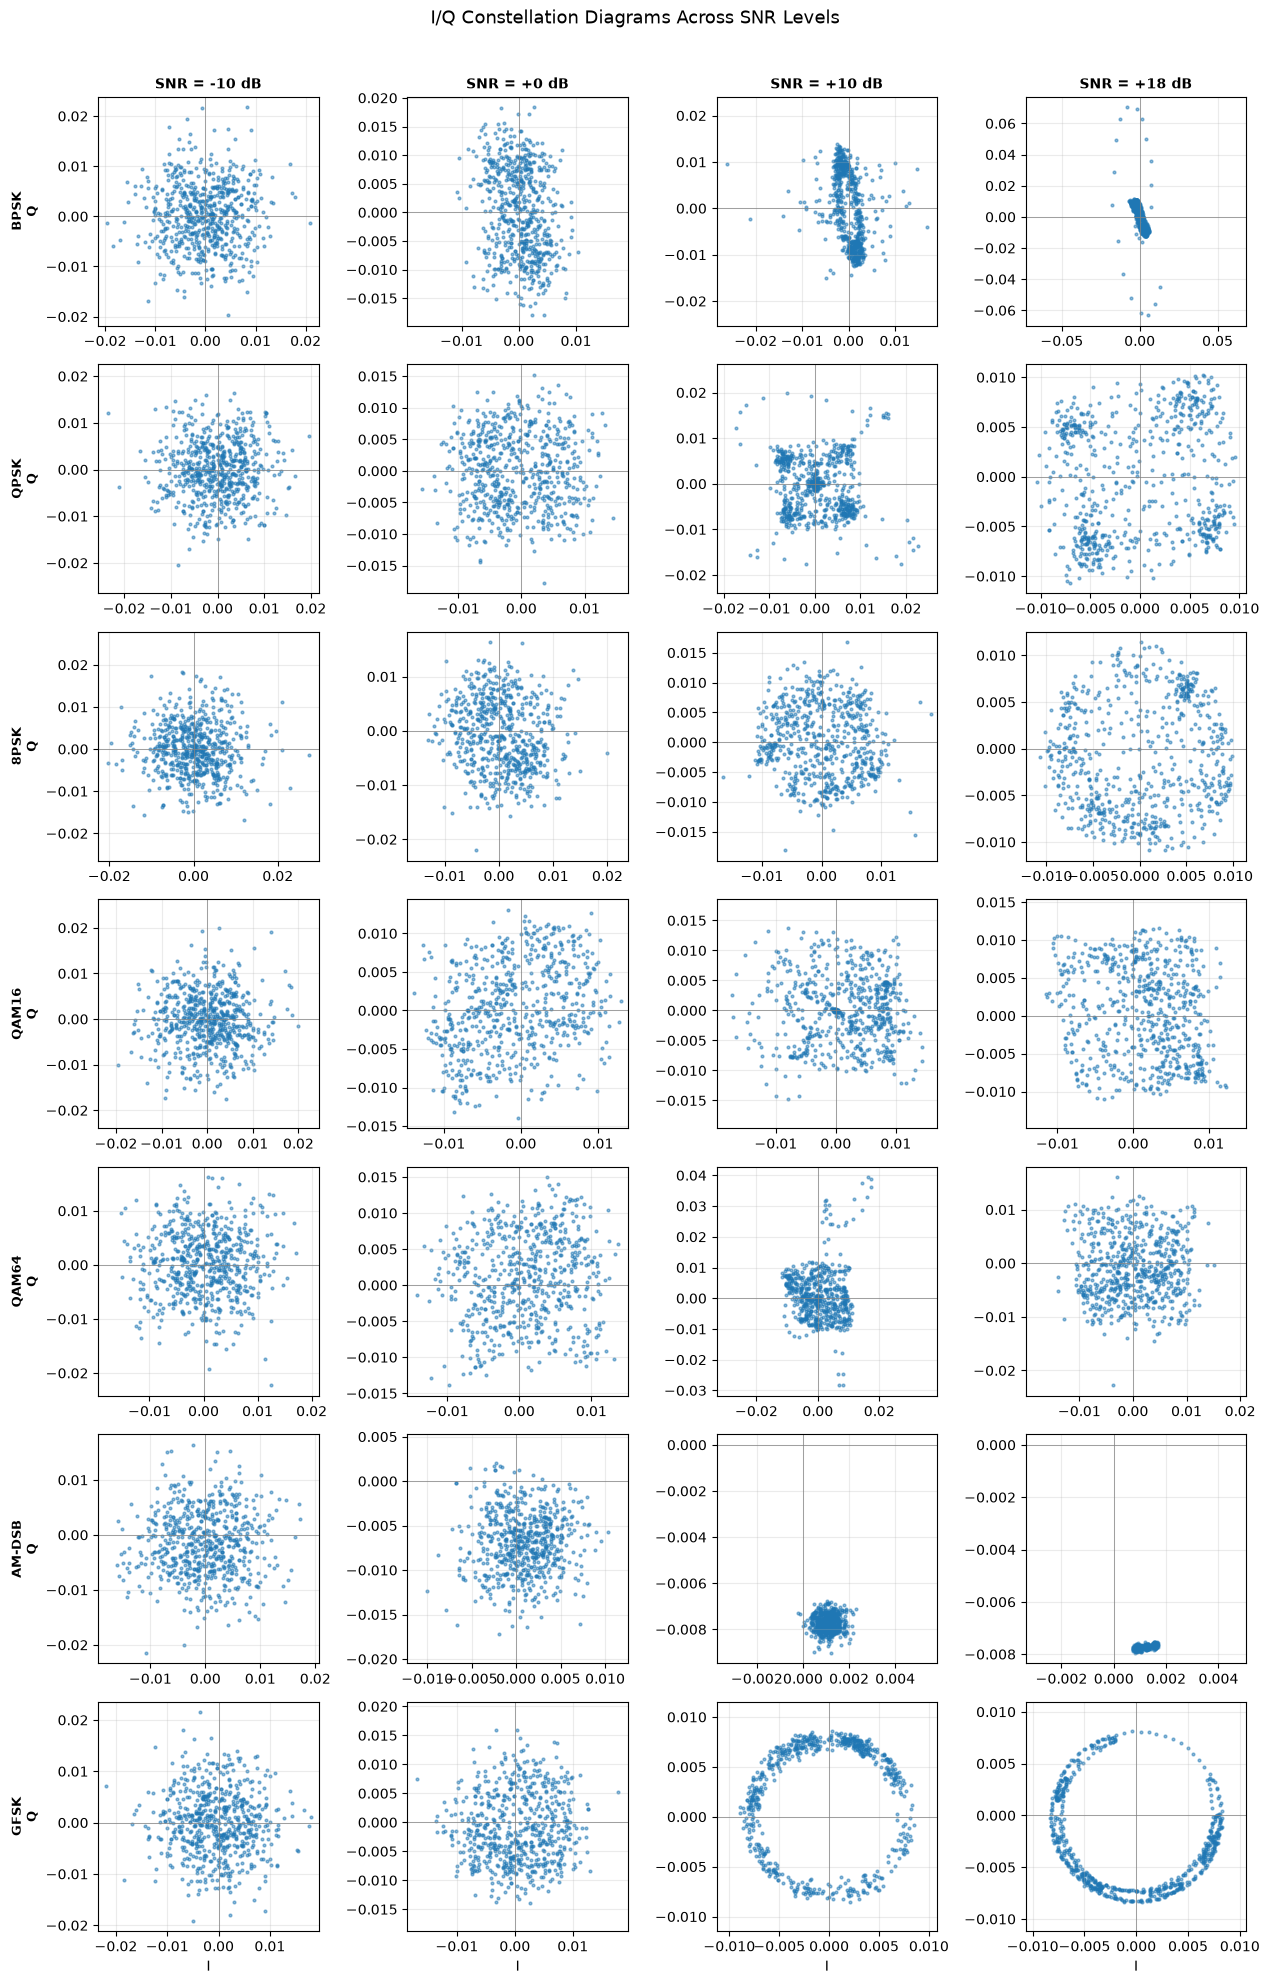

In [4]:
plot_constellation_grid(data, DEFAULT_MODULATIONS, DEFAULT_SNRS, n_frames=5)

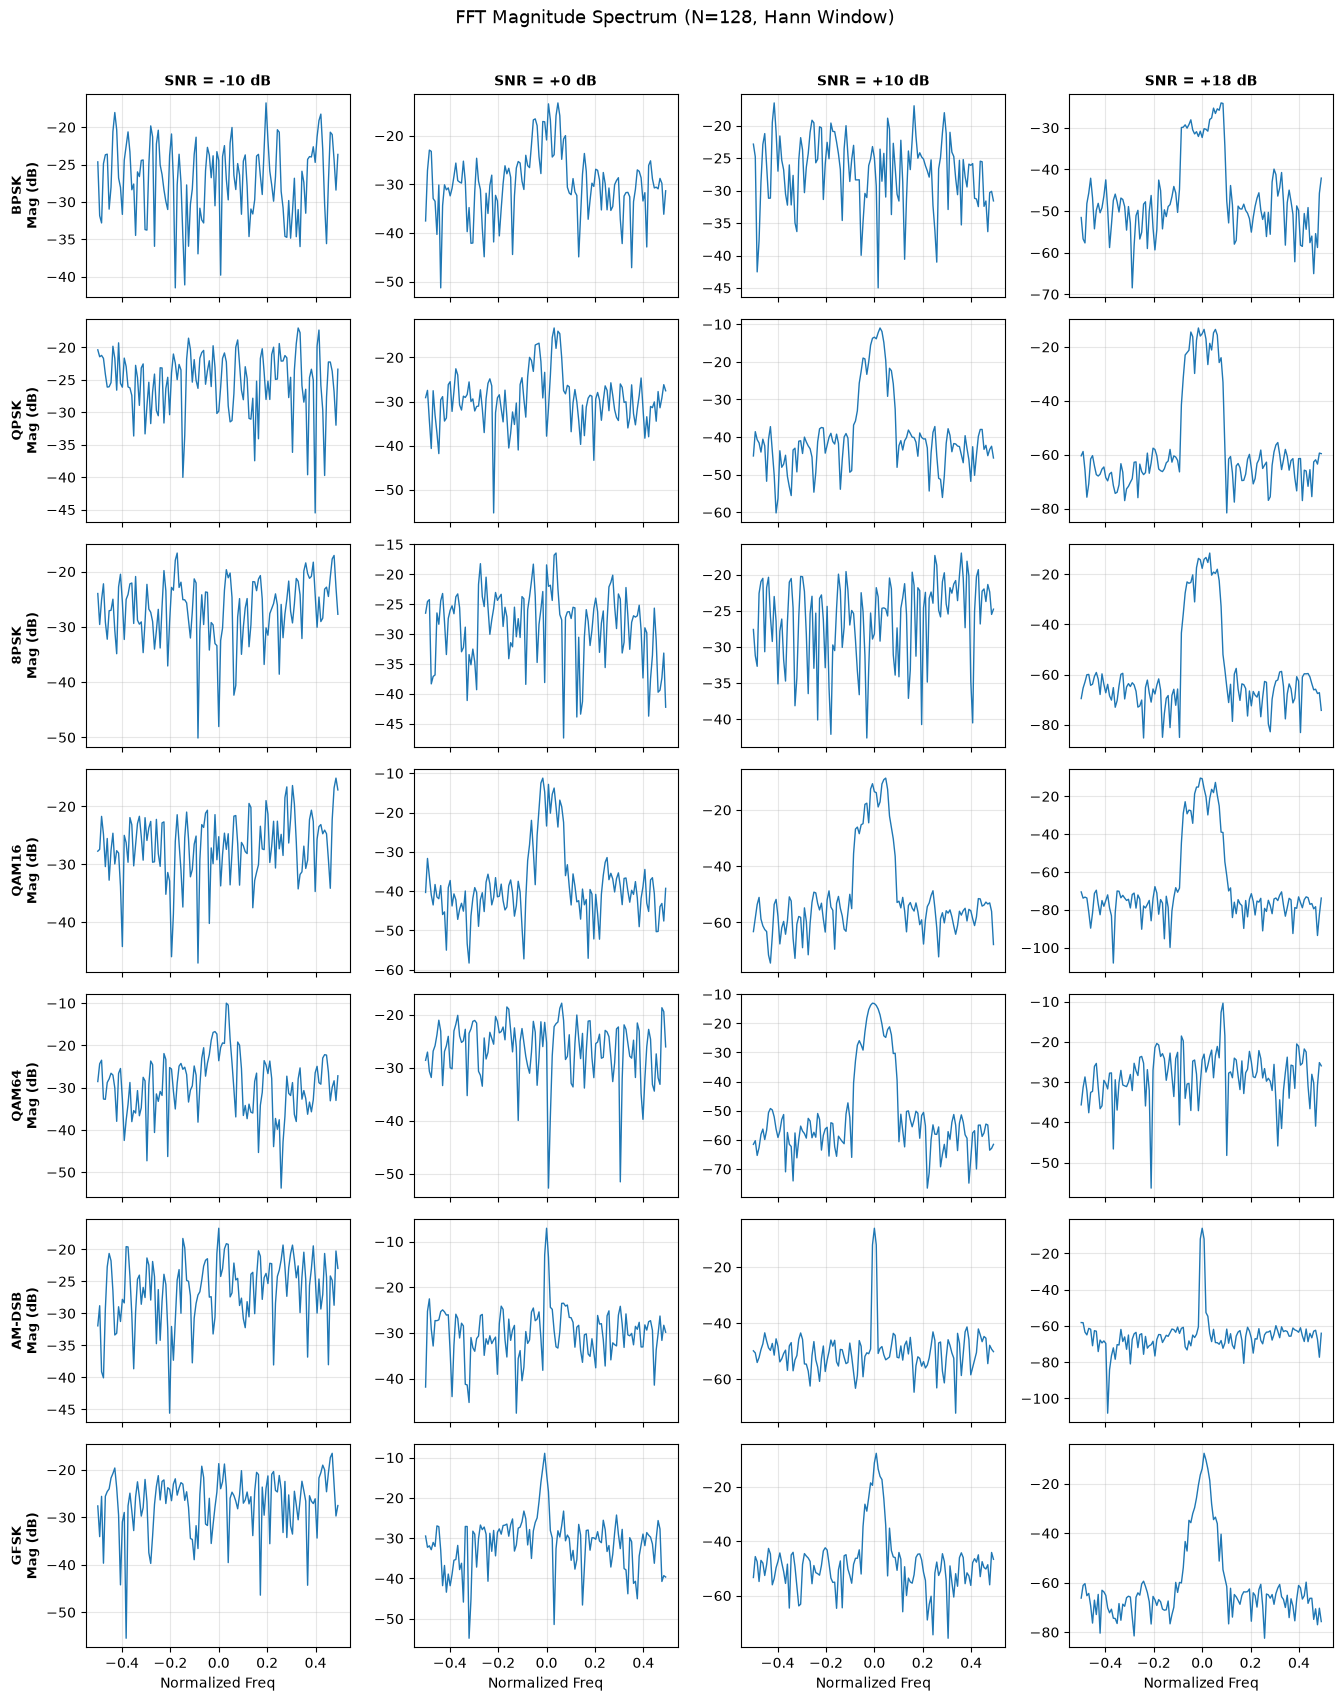

In [5]:
plot_fft_grid(data, DEFAULT_MODULATIONS, DEFAULT_SNRS, sample_idx=0, fft_len=128)